# ЛР 4. AutoML. Вариант 3 — Steel Plates Faults
## Часть 2. Анализ результатов

Читает `results/results.csv` (основной эксперимент, `run_main.sh`) и `results/h4.csv` (гипотеза H4, `run_h4.sh`).
Окружение: `lab4_base`. Все числа в отчёте берутся отсюда.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from common import run_name, get_train_test

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RES = "results/results.csv"
H4 = "results/h4.csv"
PLOTS = "results/plots"
REP = "results/automl_reports"

AUTOML = ["LightAutoML", "FEDOT", "AutoGluon"]
TUNED = ["B3_optuna"] + AUTOML   # то, у чего есть бюджет времени

res = pd.read_csv(RES)
res = res[res["split"].astype(str) == "main"]
print(len(res), "запусков")
print(res.groupby(["system", "budget_min"]).size().unstack(fill_value=0))

48 запусков
budget_min   0.0   1.0   5.0   15.0
system                             
AutoGluon       0     3     3     3
B0              3     0     0     0
B1              3     0     0     0
B2              3     0     0     0
B3_optuna       0     3     3     3
FEDOT           0     3     3     3
LightAutoML     0     3     3     3
TabPFN          3     0     0     0


### 1. Сводная таблица (среднее ± std по сидам 0, 1, 2)

In [2]:
summary = res.groupby(["system", "budget_min"]).agg(
    f1_mean=("f1_macro_test", "mean"), f1_std=("f1_macro_test", "std"),
    acc_mean=("accuracy_test", "mean"),
    train_time_s=("train_time_s", "mean"),
    pred_1000_s=("predict_time_1000_s", "mean"),
    pred_one_ms=("predict_one_ms", "mean"),
    size_mb=("size_mb", "mean"),
    peak_mem_mb=("peak_mem_mb", "mean"),
    runs=("seed", "count"),
)

# нормированный балл как в AutoML Benchmark: 0 - константа (B0), 1 - лучший результат
b0 = summary.loc[("B0", 0), "f1_mean"]
best = summary["f1_mean"].max()
summary["norm_score"] = (summary["f1_mean"] - b0) / (best - b0)

table = summary.copy()
table["F1-macro"] = table.apply(lambda r: f"{r.f1_mean:.3f} ± {r.f1_std:.3f}", axis=1)
table = table[["F1-macro", "acc_mean", "norm_score", "train_time_s", "pred_1000_s", "pred_one_ms", "size_mb", "peak_mem_mb", "runs"]]
table.round(3).to_csv("results/summary_table.csv")
table.round(3)

F1-macro  acc_mean  norm_score  train_time_s  pred_1000_s  pred_one_ms  size_mb  peak_mem_mb  runs
system      budget_min                                                                                                         
AutoGluon   1.0         0.802 ± 0.006     0.793       0.964        28.307        0.067       38.354  107.214     1256.453     3
            5.0         0.802 ± 0.006     0.793       0.964        28.599        0.065       46.101  107.214     1201.036     3
            15.0        0.802 ± 0.006     0.793       0.964        28.221        0.068       40.372  107.215     1205.385     3
B0          0.0         0.074 ± 0.000     0.347       0.000         0.003        0.000        0.010    0.001      182.219     3
B1          0.0         0.742 ± 0.000     0.728       0.884         0.029        0.001        0.425    0.005      184.135     3
B2          0.0         0.813 ± 0.005     0.793       0.978         4.703        0.001        0.249    4.007      296.172     3
B3_optuna   1.0         0.814 ± 0.006     0.801       0.980        81.326        0.001        0.274    5.398      408.281     3
            5.0         0.816 ± 0.006     0.806       0.982       321.743        0.001        0.310    4.759      428.099     3
            15.0        0.815 ± 0.005     0.803       0.981       909.429        0.001        0.278    3.195      437.953     3
FEDOT       1.0         0.791 ± 0.000     0.792       0.949        62.734        0.035       17.094    2.308      449.245     3
            5.0         0.802 ± 0.010     0.793       0.963       302.660        0.033       13.782    1.401      477.969     3
            15.0        0.787 ± 0.009     0.780       0.944       903.163        0.044       19.275    1.672      618.766     3
LightAutoML 1.0         0.823 ± 0.006     0.811       0.991        39.945        0.034       10.204   17.168      692.089     3
            5.0         0.812 ± 0.003     0.793       0.977       110.113        0.290       33.803   52.962      865.766     3
            15.0        0.812 ± 0.006     0.793       0.977       219.166        0.269       33.048   53.494      871.146     3
TabPFN      0.0         0.829 ± 0.014     0.832       1.000         0.077       59.335    36983.808   30.030     2241.797     3

### 2. Укладываются ли системы в бюджет

In [3]:
t = res[res["system"].isin(TUNED)].copy()
t["факт / бюджет"] = t["train_time_s"] / (t["budget_min"] * 60)
t.groupby(["system", "budget_min"])["факт / бюджет"].agg(["mean", "max"]).round(2)

mean   max
system      budget_min            
AutoGluon   1.0         0.47  0.50
            5.0         0.10  0.10
            15.0        0.03  0.03
B3_optuna   1.0         1.36  1.56
            5.0         1.07  1.16
            15.0        1.01  1.02
FEDOT       1.0         1.05  1.05
            5.0         1.01  1.01
            15.0        1.00  1.00
LightAutoML 1.0         0.67  0.68
            5.0         0.37  0.50
            15.0        0.24  0.29

Больше 1 — система работала дольше заявленного бюджета.

**Вывод:** строже всех бюджет соблюдает FEDOT (1.00–1.05): он останавливает эволюцию ровно по таймауту. Optuna (B3) при 1 минуте выходит за бюджет в среднем в 1.36 раза (максимум 1.56): таймаут проверяется только между испытаниями, и недоделанное последнее испытание плюс финальное обучение на всём train добавляют время; при 5 и 15 минутах превышение всего 1–7 %. LightAutoML и AutoGluon заканчивают раньше срока: LightAutoML использует 24–67 % бюджета, AutoGluon с `medium_quality` обучается ~28 с при любом бюджете (3–47 %). Поэтому у AutoGluon результаты при 1, 5 и 15 минутах совпадают, и бюджет для него — только верхняя граница.

### 3. График «качество — бюджет времени»

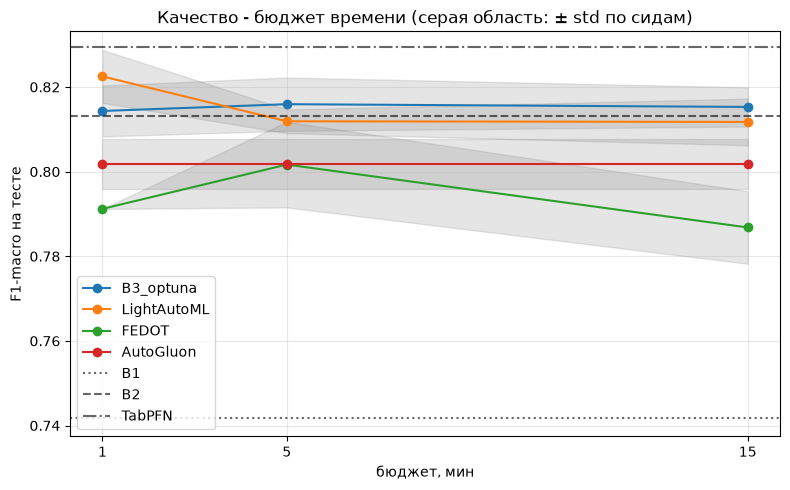

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in TUNED:
    if name not in summary.index.get_level_values(0):
        continue
    s = summary.loc[name]
    x, m, sd = s.index.values, s["f1_mean"].values, s["f1_std"].fillna(0).values
    ax.plot(x, m, marker="o", label=name)
    ax.fill_between(x, m - sd, m + sd, color="grey", alpha=0.2)
for name, ls in [("B1", ":"), ("B2", "--"), ("TabPFN", "-.")]:
    if (name, 0) in summary.index:
        ax.axhline(summary.loc[(name, 0), "f1_mean"], ls=ls, color="k", alpha=0.6, label=name)
ax.set_xticks(sorted(res.loc[res["budget_min"] > 0, "budget_min"].unique()))
ax.set_xlabel("бюджет, мин"); ax.set_ylabel("F1-macro на тесте")
ax.set_title("Качество - бюджет времени (серая область: ± std по сидам)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{PLOTS}/quality_vs_budget.png", dpi=120); plt.show()

### 4. График «качество — время предсказания»

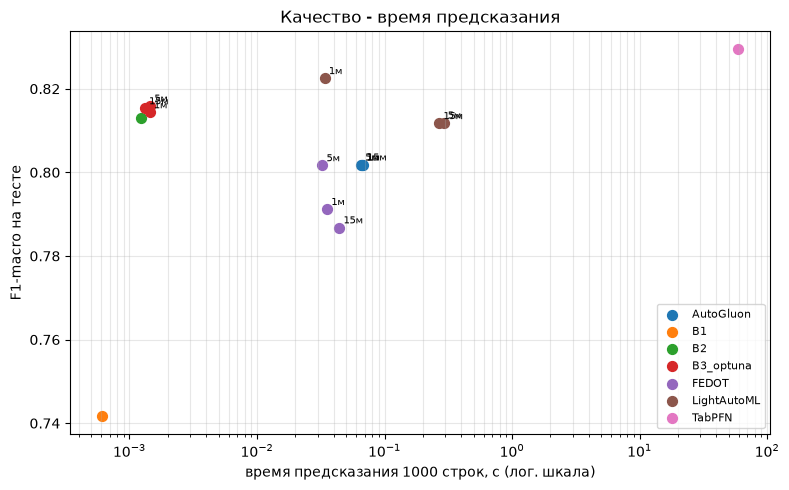

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
s = summary.reset_index()
s = s[s["system"] != "B0"]
for name, g in s.groupby("system"):
    ax.scatter(g["pred_1000_s"], g["f1_mean"], label=name, s=50)
    for _, r in g.iterrows():
        if r.budget_min > 0:
            ax.annotate(f"{r.budget_min:g}м", (r.pred_1000_s, r.f1_mean), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("время предсказания 1000 строк, с (лог. шкала)"); ax.set_ylabel("F1-macro на тесте")
ax.set_title("Качество - время предсказания")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.savefig(f"{PLOTS}/quality_vs_predict_time.png", dpi=120); plt.show()

### 5. H1. AutoML против инженера

«При одинаковом бюджете лучшая AutoML-система опережает B3, но разница меньше, чем между B3 и B1».
Правило из задания: разница меньше двух стандартных отклонений — «ничья». Берём большее из двух std (так строже).

In [6]:
def compare(a, b):
    ra, rb = summary.loc[a], summary.loc[b]
    diff = ra.f1_mean - rb.f1_mean
    sd = max(np.nan_to_num(ra.f1_std), np.nan_to_num(rb.f1_std))
    return diff, sd, abs(diff) < 2 * sd

rows = []
b1 = summary.loc[("B1", 0), "f1_mean"]
for b in sorted(res.loc[res["system"].isin(AUTOML), "budget_min"].unique()):
    cands = [(s, b) for s in AUTOML if (s, b) in summary.index]
    best_key = max(cands, key=lambda k: summary.loc[k, "f1_mean"])
    diff, sd, tie = compare(best_key, ("B3_optuna", b))
    rows.append({
        "бюджет": b, "лучший AutoML": best_key[0],
        "F1 AutoML": summary.loc[best_key, "f1_mean"], "F1 B3": summary.loc[("B3_optuna", b), "f1_mean"],
        "AutoML - B3": diff, "2*std": 2 * sd, "ничья?": tie,
        "B3 - B1": summary.loc[("B3_optuna", b), "f1_mean"] - b1,
    })
h1 = pd.DataFrame(rows).round(4)
h1

,бюджет,лучший AutoML,F1 AutoML,F1 B3,AutoML - B3,2*std,ничья?,B3 - B1
0,1.0,LightAutoML,0.8225,0.8143,0.0082,0.0125,True,0.0725
1,5.0,LightAutoML,0.8119,0.8159,-0.0040,0.0126,True,0.0741
2,15.0,LightAutoML,0.8117,0.8153,-0.0036,0.0110,True,0.0735


**Вывод по H1:** гипотеза **не подтвердилась** в части «AutoML опережает B3». Лучшая AutoML-система при всех бюджетах — LightAutoML, её разница с B3: +0.008 (1 мин), −0.004 (5 мин), −0.004 (15 мин), везде меньше 2σ (0.011–0.013), то есть ничья. Вторая часть верна: B3 лучше B1 на 0.073–0.074, это примерно в 10 раз больше разницы AutoML − B3. Итог: на этом датасете CatBoost с подбором гиперпараметров так же хорош, как AutoML, и даже CatBoost по умолчанию (B2, 0.813) почти не уступает. **Сравнение с прогнозом:** мы прогнозировали «подтвердится» и ошиблись в первой части: ожидали, что AutoML (прежде всего AutoGluon за счёт стекинга) хоть немного обгонит бустинг, а получили ничью, причём AutoGluon оказался даже ниже B3 (0.802 против 0.814–0.816), потому что при `medium_quality` он вообще не строит стек. Вторую часть (B3 ≫ B1) угадали.

### 6. H2. Российский против зарубежного

«Разница в качестве между российской и зарубежной системой незначима (меньше разброса по сидам), а время инференса и размер модели отличаются в разы».

In [7]:
rows = []
for b in sorted(res.loc[res["system"].isin(AUTOML), "budget_min"].unique()):
    for rus in ["LightAutoML", "FEDOT"]:
        if (rus, b) not in summary.index or ("AutoGluon", b) not in summary.index:
            continue
        diff, sd, tie = compare((rus, b), ("AutoGluon", b))
        r, a = summary.loc[(rus, b)], summary.loc[("AutoGluon", b)]
        rows.append({
            "бюджет": b, "пара": f"{rus} vs AutoGluon", "разница F1": diff, "2*std": 2 * sd, "ничья?": tie,
            "время 1000 строк (рус/AG)": r.pred_1000_s / a.pred_1000_s,
            "одно предсказание (рус/AG)": r.pred_one_ms / a.pred_one_ms,
            "размер (рус/AG)": r.size_mb / a.size_mb,
            "память (рус/AG)": r.peak_mem_mb / a.peak_mem_mb,
        })
h2 = pd.DataFrame(rows).round(3)
h2

,бюджет,пара,разница F1,2*std,ничья?,время 1000 строк (рус/AG),одно предсказание (рус/AG),размер (рус/AG),память (рус/AG)
0,1.0,LightAutoML vs AutoGluon,0.021,0.013,False,0.508,0.266,0.160,0.551
1,1.0,FEDOT vs AutoGluon,-0.011,0.012,True,0.531,0.446,0.022,0.358
2,5.0,LightAutoML vs AutoGluon,0.010,0.012,True,4.435,0.733,0.494,0.721
3,5.0,FEDOT vs AutoGluon,-0.000,0.020,True,0.497,0.299,0.013,0.398
4,15.0,LightAutoML vs AutoGluon,0.010,0.012,True,3.962,0.819,0.499,0.723
5,15.0,FEDOT vs AutoGluon,-0.015,0.017,True,0.652,0.477,0.016,0.513


Отношение > 1 — у российской системы больше (медленнее / тяжелее).

**Вывод по H2:** гипотеза **в основном подтвердилась**. По качеству в 5 парах из 6 ничья; исключение — бюджет 1 мин, где LightAutoML лучше AutoGluon на 0.021 при 2σ = 0.013. Ресурсы действительно отличаются в разы, но в разные стороны: модель FEDOT в 45–75 раз меньше модели AutoGluon (1.4–2.3 МБ против 107 МБ) и предсказывает 1000 строк примерно в 2 раза быстрее; LightAutoML в 2–6 раз меньше AutoGluon, но при бюджетах 5 и 15 мин предсказывает 1000 строк примерно в 4 раза медленнее (бленд из нескольких моделей, каждая по 5 фолдам). Одно предсказание у всех трёх систем занимает 10–50 мс, у CatBoost (B2) — 0.25 мс.

**Сравнение с прогнозом:** прогноз «подтвердится» сбылся, но объяснение оказалось неверным. Мы думали, что AutoGluon тяжелее, потому что строит многоуровневые ансамбли, а LightAutoML и FEDOT нет. На деле всё наоборот: при `medium_quality` итоговый ансамбль AutoGluon — это одна модель с весом 1.0 (LightGBMXT или XGBoost), а 107 МБ на диске занимают все 11 обученных моделей-кандидатов, которые он сохраняет. LightAutoML строит двухуровневый стек с блендингом (на втором уровне линейная модель + LightGBM, каждая по 5 фолдам), а FEDOT — граф из нескольких моделей (catboost, xgboost, lgbm → logit).

### 7. H4. Малые данные

«При 1–2 тысячах строк разброс метрики по сидам и разбиениям больше, чем разница между AutoML-системами. TabPFN не хуже AutoML и в десятки раз быстрее».
6 разбиений: основное (`main`) + 5 случайных (`100`–`104`). AutoML с бюджетом 5 минут, сид 0.

system,AutoGluon,B2,LightAutoML,TabPFN
split,,,,
100,0.810,0.836,0.850,0.867
101,0.794,0.821,0.805,0.837
102,0.843,0.846,0.860,0.873
103,0.830,0.854,0.830,0.871
104,0.823,0.843,0.843,0.864
main,0.797,0.807,0.815,0.842


,F1 среднее по разбиениям,std по разбиениям,размах (max-min),"fit+predict, с"
system,,,,
AutoGluon,0.816,0.019,0.049,29.594
B2,0.834,0.017,0.047,4.923
LightAutoML,0.834,0.021,0.055,100.062
TabPFN,0.859,0.016,0.037,23.557


разница LightAutoML - AutoGluon по разбиениям: среднее 0.017, |среднее| 0.017
std по сидам (основное разбиение, бюджет 5):
system
AutoGluon      0.0059
FEDOT          0.0101
LightAutoML    0.0028
Name: f1_macro_test, dtype: float64


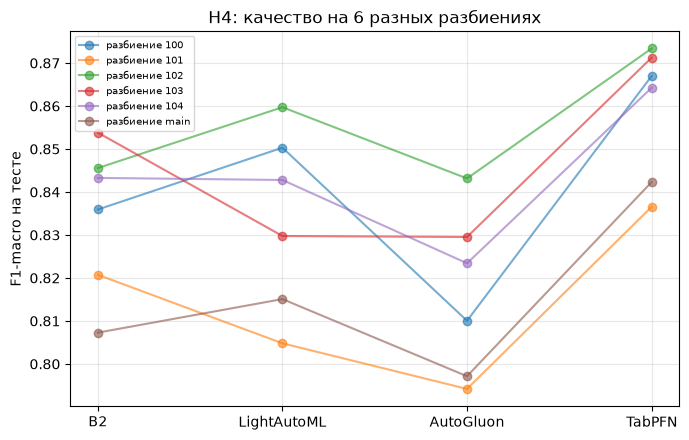

In [8]:
if os.path.exists(H4):
    h4 = pd.read_csv(H4)
    main_part = res[((res["system"].isin(["LightAutoML", "AutoGluon"])) & (res["budget_min"] == 5) & (res["seed"] == 0))
                    | ((res["system"].isin(["B2", "TabPFN"])) & (res["seed"] == 0))]
    h4 = pd.concat([h4, main_part], ignore_index=True)
    h4["split"] = h4["split"].astype(str)
    n_test = len(get_train_test("main")[1])
    # у TabPFN "обучение" почти 0 с, вся работа в предсказании, поэтому сравниваем обучение + предсказание теста
    h4["fit+predict_s"] = h4["train_time_s"] + h4["predict_time_1000_s"] * n_test / 1000

    pivot = h4.pivot_table(index="split", columns="system", values="f1_macro_test")
    display(pivot.round(3))

    stats = pd.DataFrame({
        "F1 среднее по разбиениям": pivot.mean(),
        "std по разбиениям": pivot.std(),
        "размах (max-min)": pivot.max() - pivot.min(),
        "fit+predict, с": h4.groupby("system")["fit+predict_s"].mean(),
    })
    display(stats.round(3))

    d = (pivot["LightAutoML"] - pivot["AutoGluon"])
    print(f"разница LightAutoML - AutoGluon по разбиениям: среднее {d.mean():.3f}, |среднее| {d.abs().mean():.3f}")
    print("std по сидам (основное разбиение, бюджет 5):")
    print(res[(res.budget_min == 5) & res.system.isin(AUTOML)].groupby("system")["f1_macro_test"].std().round(4))

    fig, ax = plt.subplots(figsize=(7, 4.5))
    order = [c for c in ["B2", "LightAutoML", "AutoGluon", "TabPFN"] if c in pivot.columns]
    for sp, row in pivot[order].iterrows():
        ax.plot(order, row.values, marker="o", alpha=0.6, label=f"разбиение {sp}")
    ax.set_ylabel("F1-macro на тесте"); ax.set_title("H4: качество на 6 разных разбиениях")
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{PLOTS}/h4_splits.png", dpi=120); plt.show()
else:
    print("нет results/h4.csv - сначала запустить run_h4.sh")

**Вывод по H4:** гипотеза **подтвердилась частично**.
1. Разброс по разбиениям (std 0.016–0.021, размах 0.037–0.055) больше разброса по сидам (0.003–0.010) и сравним с разницей LightAutoML − AutoGluon (в среднем 0.017). Значит, по одному разбиению выводы делать опасно — эта часть подтвердилась. Но разница систем при этом систематическая: LightAutoML не хуже AutoGluon на всех 6 разбиениях, а TabPFN лучший на всех 6.
2. «TabPFN не хуже AutoML» — подтвердилось, он даже лучше: 0.859 против 0.834 у LightAutoML и B2 и 0.816 у AutoGluon.
3. «TabPFN в десятки раз быстрее» — опровергнуто. Обучение + предсказание теста: TabPFN 23.6 с, LightAutoML 100 с (в 4 раза дольше), AutoGluon 29.6 с (в 1.3 раза), а CatBoost по умолчанию — 4.9 с, быстрее TabPFN. На CPU у TabPFN почти всё время уходит на предсказание: ~60 с на 1000 строк против 0.07–0.3 с у AutoML.

**Сравнение с прогнозом:** все три части угадали (да / да / нет). Уточнение к нашему объяснению: TabPFN не «дообучается» под задачу — его веса не меняются, обучающая выборка просто подаётся на вход вместе с тестом (in-context learning), поэтому `fit` почти мгновенный, а вся цена переносится на предсказание.

### 8. Ошибки лучшей модели: матрица ошибок и F1 по классам

лучшая конфигурация по среднему F1: TabPFN бюджет 0.0 | файл: TabPFN_b0_s0_main
              precision    recall  f1-score   support

       Bumps      0.824     0.691     0.752        81
   Dirtiness      0.786     1.000     0.880        11
   K_Scratch      0.987     0.949     0.967        78
Other_Faults      0.789     0.859     0.823       135
      Pastry      0.656     0.656     0.656        32
      Stains      0.857     0.857     0.857        14
   Z_Scratch      0.949     0.974     0.961        38

    accuracy                          0.841       389
   macro avg      0.835     0.855     0.842       389
weighted avg      0.843     0.841     0.840       389



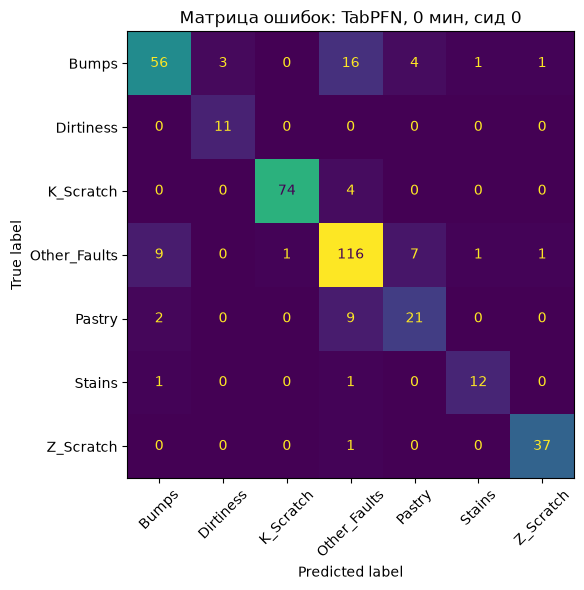

In [9]:
cands = summary.reset_index()
cands = cands[cands["system"].isin(TUNED + ["TabPFN", "B2"])]
best_row = cands.sort_values("f1_mean", ascending=False).iloc[0]
name = run_name(best_row.system, best_row.budget_min, 0, "main")
print("лучшая конфигурация по среднему F1:", best_row.system, "бюджет", best_row.budget_min, "| файл:", name)

p = pd.read_csv(f"results/preds/{name}.csv")
print(classification_report(p.y_true, p.y_pred, digits=3))
labels = sorted(p.y_true.unique())
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(p.y_true, p.y_pred, labels=labels), display_labels=labels).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title(f"Матрица ошибок: {best_row.system}, {best_row.budget_min:g} мин, сид 0")
plt.tight_layout(); plt.savefig(f"{PLOTS}/confusion_best.png", dpi=120); plt.show()

### 9. Что выбрал каждый AutoML (бюджет 15 минут, сид 0)

In [10]:
for sys_name in AUTOML:
    f = f"{REP}/{run_name(sys_name, 15, 0, 'main')}_structure.txt"
    print("=" * 20, sys_name, "=" * 20)
    print(open(f).read()[:3000] if os.path.exists(f) else "нет файла " + f)

==================== LightAutoML ====================
Models on level 0:
	 5 averaged models Lvl_0_Pipe_0_Mod_0_LinearL2
	 5 averaged models Lvl_0_Pipe_1_Mod_0_LightGBM
	 5 averaged models Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM
	 5 averaged models Lvl_0_Pipe_1_Mod_2_CatBoost
	 5 averaged models Lvl_0_Pipe_1_Mod_3_Tuned_CatBoost

Final prediction for new objects (level 1) = 
	 0.85325 * (5 averaged models Lvl_1_Pipe_0_Mod_0_LinearL2) +
	 0.14675 * (5 averaged models Lvl_1_Pipe_1_Mod_0_LightGBM) 
==================== FEDOT ====================
{'depth': 4, 'length': 6, 'nodes': [logit, catboost, scaling, resample, xgboost, lgbm]}

logit: parents=['catboost', 'xgboost', 'lgbm'] params={'C': 4.010430804214427}
catboost: parents=['scaling'] params={'n_jobs': 4, 'num_trees': 3000, 'learning_rate': 0.03, 'l2_leaf_reg': 0.01, 'bootstrap_type': 'Bernoulli', 'grow_policy': 'SymmetricTree', 'max_depth': 5, 'min_data_in_leaf': 1, 'one_hot_max_size': 10, 'fold_permutation_block': 1, 'boosting_type': 'Pl

In [11]:
f = f"{REP}/{run_name('AutoGluon', 15, 0, 'main')}_leaderboard.csv"
if os.path.exists(f):
    display(pd.read_csv(f)[["model", "score_val", "fit_time", "pred_time_val", "stack_level"]].head(12))

,model,score_val,fit_time,pred_time_val,stack_level
0,LightGBMXT,0.835812,3.599528,0.006747,1
1,WeightedEnsemble_L2,0.835812,3.708653,0.007810,2
2,CatBoost,0.825352,7.744022,0.001316,1
3,LightGBM,0.822660,3.111556,0.009820,1
4,XGBoost,0.816720,1.558609,0.002603,1
5,LightGBMLarge,0.801618,7.854256,0.017210,1
6,NeuralNetTorch,0.788901,2.648696,0.003476,1
7,RandomForestEntr,0.788888,0.277249,0.026209,1
8,ExtraTreesGini,0.779993,0.243801,0.026041,1
9,NeuralNetFastAI,0.758283,0.796060,0.004790,1


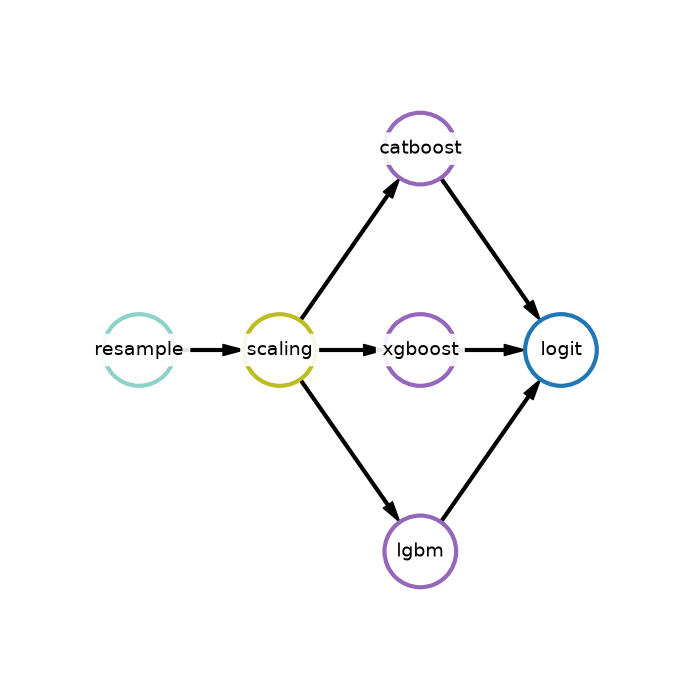

In [12]:
from IPython.display import Image
f = f"{REP}/{run_name('FEDOT', 15, 0, 'main')}_pipeline.png"
Image(f) if os.path.exists(f) else print("нет картинки пайплайна FEDOT")

### 10. Важность признаков: AutoML против CatBoost

In [13]:
imp = {}
for b in [15, 5, 1]:   # берём самый большой бюджет, который есть
    f = f"{REP}/{run_name('LightAutoML', b, 0, 'main')}_importance.csv"
    if os.path.exists(f):
        t = pd.read_csv(f); imp["LightAutoML"] = t.set_index(t.columns[0])[t.columns[1]]; break
f = f"{REP}/{run_name('AutoGluon', 5, 0, 'main')}_importance.csv"
if os.path.exists(f):
    imp["AutoGluon"] = pd.read_csv(f, index_col=0)["importance"]
f = f"{REP}/catboost_B2_importance.csv"
if os.path.exists(f):
    imp["CatBoost (B2)"] = pd.read_csv(f, index_col=0).iloc[:, 0]

ranks = pd.DataFrame({k: v.rank(ascending=False) for k, v in imp.items()})
ranks["средний ранг"] = ranks.mean(axis=1)
ranks.sort_values("средний ранг").head(10)

,LightAutoML,AutoGluon,CatBoost (B2),средний ранг
Length_of_Conveyer,3.0,2.0,1.0,2.000000
Steel_Plate_Thickness,1.0,3.0,2.0,2.000000
TypeOfSteel_A300,6.0,1.0,8.0,5.000000
Orientation_Index,5.0,6.0,4.0,5.000000
Square_Index,9.0,4.0,9.0,7.333333
Edges_Index,11.0,9.0,3.0,7.666667
X_Minimum,10.0,5.0,10.0,8.333333
Minimum_of_Luminosity,7.0,15.0,5.0,9.000000
Empty_Index,15.0,8.0,6.0,9.666667
Y_Maximum,8.0,16.0,11.0,11.666667


Место признака (1 — самый важный) у каждой системы.

**Сравнение с интуицией:** интуитивно ожидали, что тип дефекта определяется его формой и яркостью (площадь, периметры, индексы формы). На деле у всех трёх моделей наверху параметры листа: Length_of_Conveyer и Steel_Plate_Thickness (средний ранг 2), затем TypeOfSteel_A300 и Orientation_Index. Отчасти это может быть физикой процесса (разные дефекты характерны для разных марок и толщин), но это совпадает с находкой EDA про «псевдолисты»: модель частично узнаёт лист, а не дефект. В топе модели согласны, дальше расходятся (Edges_Index — 3-е место у CatBoost и 11-е у LightAutoML): важность у разных методов считается по-разному, а у дублирующих признаков она делится.

### 11. Внедряемость: число строк кода

In [14]:
for f in sorted(glob.glob("run_*.py")):
    lines = [l for l in open(f, encoding="utf-8") if l.strip() and not l.strip().startswith("#")]
    print(f"{f:22s} {len(lines)} строк")

run_autogluon.py       48 строк
run_b3_optuna.py       55 строк
run_baselines.py       58 строк
run_fedot.py           55 строк
run_lama.py            49 строк
run_tabpfn.py          34 строк


### 12. Бонус: ограничения внедрения (≤ 50 МБ, ≤ 10 мс на одно предсказание)

In [15]:
ok = summary.reset_index()
ok = ok[(ok["size_mb"] <= 50) & (ok["pred_one_ms"] <= 10) & (ok["system"] != "B0")]
ok.sort_values("f1_mean", ascending=False)[["system", "budget_min", "f1_mean", "f1_std", "size_mb", "pred_one_ms"]].round(3).head(10)

,system,budget_min,f1_mean,f1_std,size_mb,pred_one_ms
7,B3_optuna,5.0,0.816,0.006,4.759,0.310
8,B3_optuna,15.0,0.815,0.005,3.195,0.278
6,B3_optuna,1.0,0.814,0.006,5.398,0.274
5,B2,0.0,0.813,0.005,4.007,0.249
4,B1,0.0,0.742,0.000,0.005,0.425


**Вывод:** под оба ограничения (≤ 50 МБ и ≤ 10 мс) проходят только CatBoost-модели: B3 (F1 0.814–0.816, 3–5 МБ, ~0.3 мс) и B2 (0.813, 4 МБ, 0.25 мс). Лучшая модель без ограничений — TabPFN (0.829) — не проходит по скорости (~37 с на одно предсказание на CPU). Потеря качества: 0.829 − 0.816 = 0.013 F1-macro (~1.6 %), это даже меньше разброса самого TabPFN по сидам (±0.014). Ближе всех из AutoML — LightAutoML с бюджетом 1 мин: 0.823 и 17 МБ, но 10.2 мс на предсказание, чуть выше порога. Для внедрения выбираем CatBoost (B3 или B2).